# Figure 4 — soil model enabled

Same main figure layout, observations, snow pits, colors, periods, and lapse-rate forcing datasets as `4_figure4.ipynb`, using the existing **soil** runs at the original **+1.2°C (274.35 K)** precipitation threshold. The soil model and soil flux are enabled in those established runs; no threshold-sensitivity output is used. No new simulations are needed.

The raw-forcing supplementary comparison remains in the original notebook: corresponding raw-forcing soil outputs are unavailable. Final exports are opt-in with `SAVE_FIGURES` and use `figure4_soil.*` filenames to keep them separate from the base figure.


In [1]:
# import packages 
%matplotlib inline

# plotting packages 
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns 
import matplotlib.dates as mdates

sns.set_theme()
plt.rcParams['figure.figsize'] = [12,6] #overriding size

# data packages 
import pandas as pd
import numpy as np
import xarray as xr
from datetime import datetime

import scipy
import os
# Display figures inline. Set True only when exporting selected final figures.
SAVE_FIGURES = False


In [2]:
pwd

'/home/cassie/python/repos/snow_modeling_point/sites/all_sites'

# Open Data and Model Simulations

## Function for Reading SMET Files 

In [3]:
def read_smet(filepath):
    header = {}
    fields = None
    data_start = None

    # Read file and parse header
    with open(filepath, "r") as f:
        lines = f.readlines()

    for i, line in enumerate(lines):
        line = line.strip()

        # Detect fields line
        if line.startswith("fields"):
            fields = line.split("=")[1].strip().split()

        # Detect start of data
        if line == "[DATA]":
            data_start = i + 1
            break

        # Parse header key-value pairs
        if "=" in line and not line.startswith("["):
            key, value = line.split("=", 1)
            header[key.strip()] = value.strip()

    if fields is None:
        raise ValueError("No 'fields' line found in SMET header.")
    if data_start is None:
        raise ValueError("No [DATA] section found.")

    # Read data into DataFrame
    df = pd.read_csv(
        filepath,
        skiprows=data_start,
        sep=r"\s+",
        names=fields,
        parse_dates=["timestamp"]
    )

    # Set timestamp as index
    df = df.set_index("timestamp")

    # Convert to xarray
    ds = xr.Dataset.from_dataframe(df)

    return ds, header

### Open SNOWPACK SMet Output

In [4]:
# HRRR-AK Files First 

# HRRR-AK Lapse-rate Files 
ds_snowpack_hrrrak_lapserate_ppsa, header_hrrrak_lapserate_ppsa = read_smet("/home/cassie/python/models/run_snowpack/sites/ppsa/output/hrrrak_lapserate_ppsa_WY2020-WY2025_soil.smet")
ds_snowpack_hrrrak_lapserate_tram, header_hrrrak_lapserate_tram = read_smet("/home/cassie/python/models/run_snowpack/sites/tram/output/hrrrak_lapserate_tram_WY2020-WY2025_soil.smet")
ds_snowpack_hrrrak_lapserate_heen, header_hrrrak_lapserate_heen = read_smet("/home/cassie/python/models/run_snowpack/sites/heen/output/hrrrak_lapserate_heen_WY2020-WY2025_soil.smet")

# Met HRRR-AK Files now

# Met HRRR-AK Lapse-rate Files
ds_snowpack_met_hrrrak_lapserate_ppsa, header_met_hrrrak_lapserate_ppsa = read_smet("/home/cassie/python/models/run_snowpack/sites/ppsa/output/met_hrrrak_lapserate_ppsa_WY2020-WY2025_soil.smet") # ppsa has WY2020-WY2025
ds_snowpack_met_hrrrak_lapserate_tram, header_met_hrrrak_lapserate_tram = read_smet("/home/cassie/python/models/run_snowpack/sites/tram/output/met_hrrrak_lapserate_tram_WY2023-WY2025_soil.smet")
ds_snowpack_met_hrrrak_lapserate_heen, header_met_hrrrak_lapserate_heen = read_smet("/home/cassie/python/models/run_snowpack/sites/heen/output/met_hrrrak_lapserate_heen_WY2020-WY2022_soil.smet") # heen doesn't have until 2025


### Open Observations

In [5]:
# open observations

# HEEN 
file_heen = "/hdd/snow_hydrology/met_station/snotel/heenlatinee/heen_met_2016_2026_cleaned_v1.nc"
ds_obs_heen = xr.open_dataset(file_heen)
ds_obs_heen = ds_obs_heen.sel(time=slice("2019-10-01", "2025-09-30"))

#PPSA 
file_ppsa = "/hdd/snow_hydrology/met_station/ppsa2/pppsa_met_station_data_synoptic_2026-03-20" 
ds_obs_ppsa = xr.open_dataset(file_ppsa)
ds_obs_ppsa = ds_obs_ppsa.sel(time=slice("2019-10-01", "2025-09-30"))


# TRAM 
file_tram = "/hdd/snow_hydrology/met_station/tram/tram_met_station_data_synoptic_2026-03-20"  
ds_obs_tram = xr.open_dataset(file_tram)
ds_obs_tram = ds_obs_tram.sel(time=slice("2019-10-01", "2025-09-30"))

In [6]:
# pick colors for each site and stick to them across all plots
ppsa_color = 'darkviolet'
tram_color = 'maroon'
heen_color = 'teal'

# color hrrr-ak model 
hrrrak_color = 'tab:blue'
hrrrak_lapserate_color = 'tab:orange'
met_hrrrak_color = 'tab:green'
obs_color = 'tab:gray'

Cut to just three years each

In [7]:
ds_obs_heen = ds_obs_heen.sel(time=slice("2019-09-01", "2022-09-30"))
ds_obs_ppsa = ds_obs_ppsa.sel(time=slice("2022-09-01", "2025-09-30"))
ds_obs_tram = ds_obs_tram.sel(time=slice("2022-09-01", "2025-09-30"))

And the field measurements of snow depth to add to PPSA, 

In [8]:
# df created in repo/juneau_field_data/1_create_snowpit_dataframe_WY2025.ipynb
# df.to_csv('/hdd/snow_hydrology/field_data/snow_pit_swe_measurements_WY2025.csv')
df_field_measurements = pd.read_csv('/hdd/snow_hydrology/field_data/snow_pit_swe_measurements_WY2025.csv', index_col=0, parse_dates=True)
df_field_measurements.head()

,snow_depth_cm,snow_depth_in,average_density,swe_mm,swe_m,swe_in
2025-01-23,126,49.606299,334,420.80,0.42080,16.566929
2025-01-28,123,48.425197,317,389.84,0.38984,15.348031
2025-02-12,133,52.362205,334,444.00,0.44400,17.480315
2025-02-16,130,51.181102,334,434.00,0.43400,17.086614
2025-02-20,128,50.393701,306,391.68,0.39168,15.420472


# Figure 4


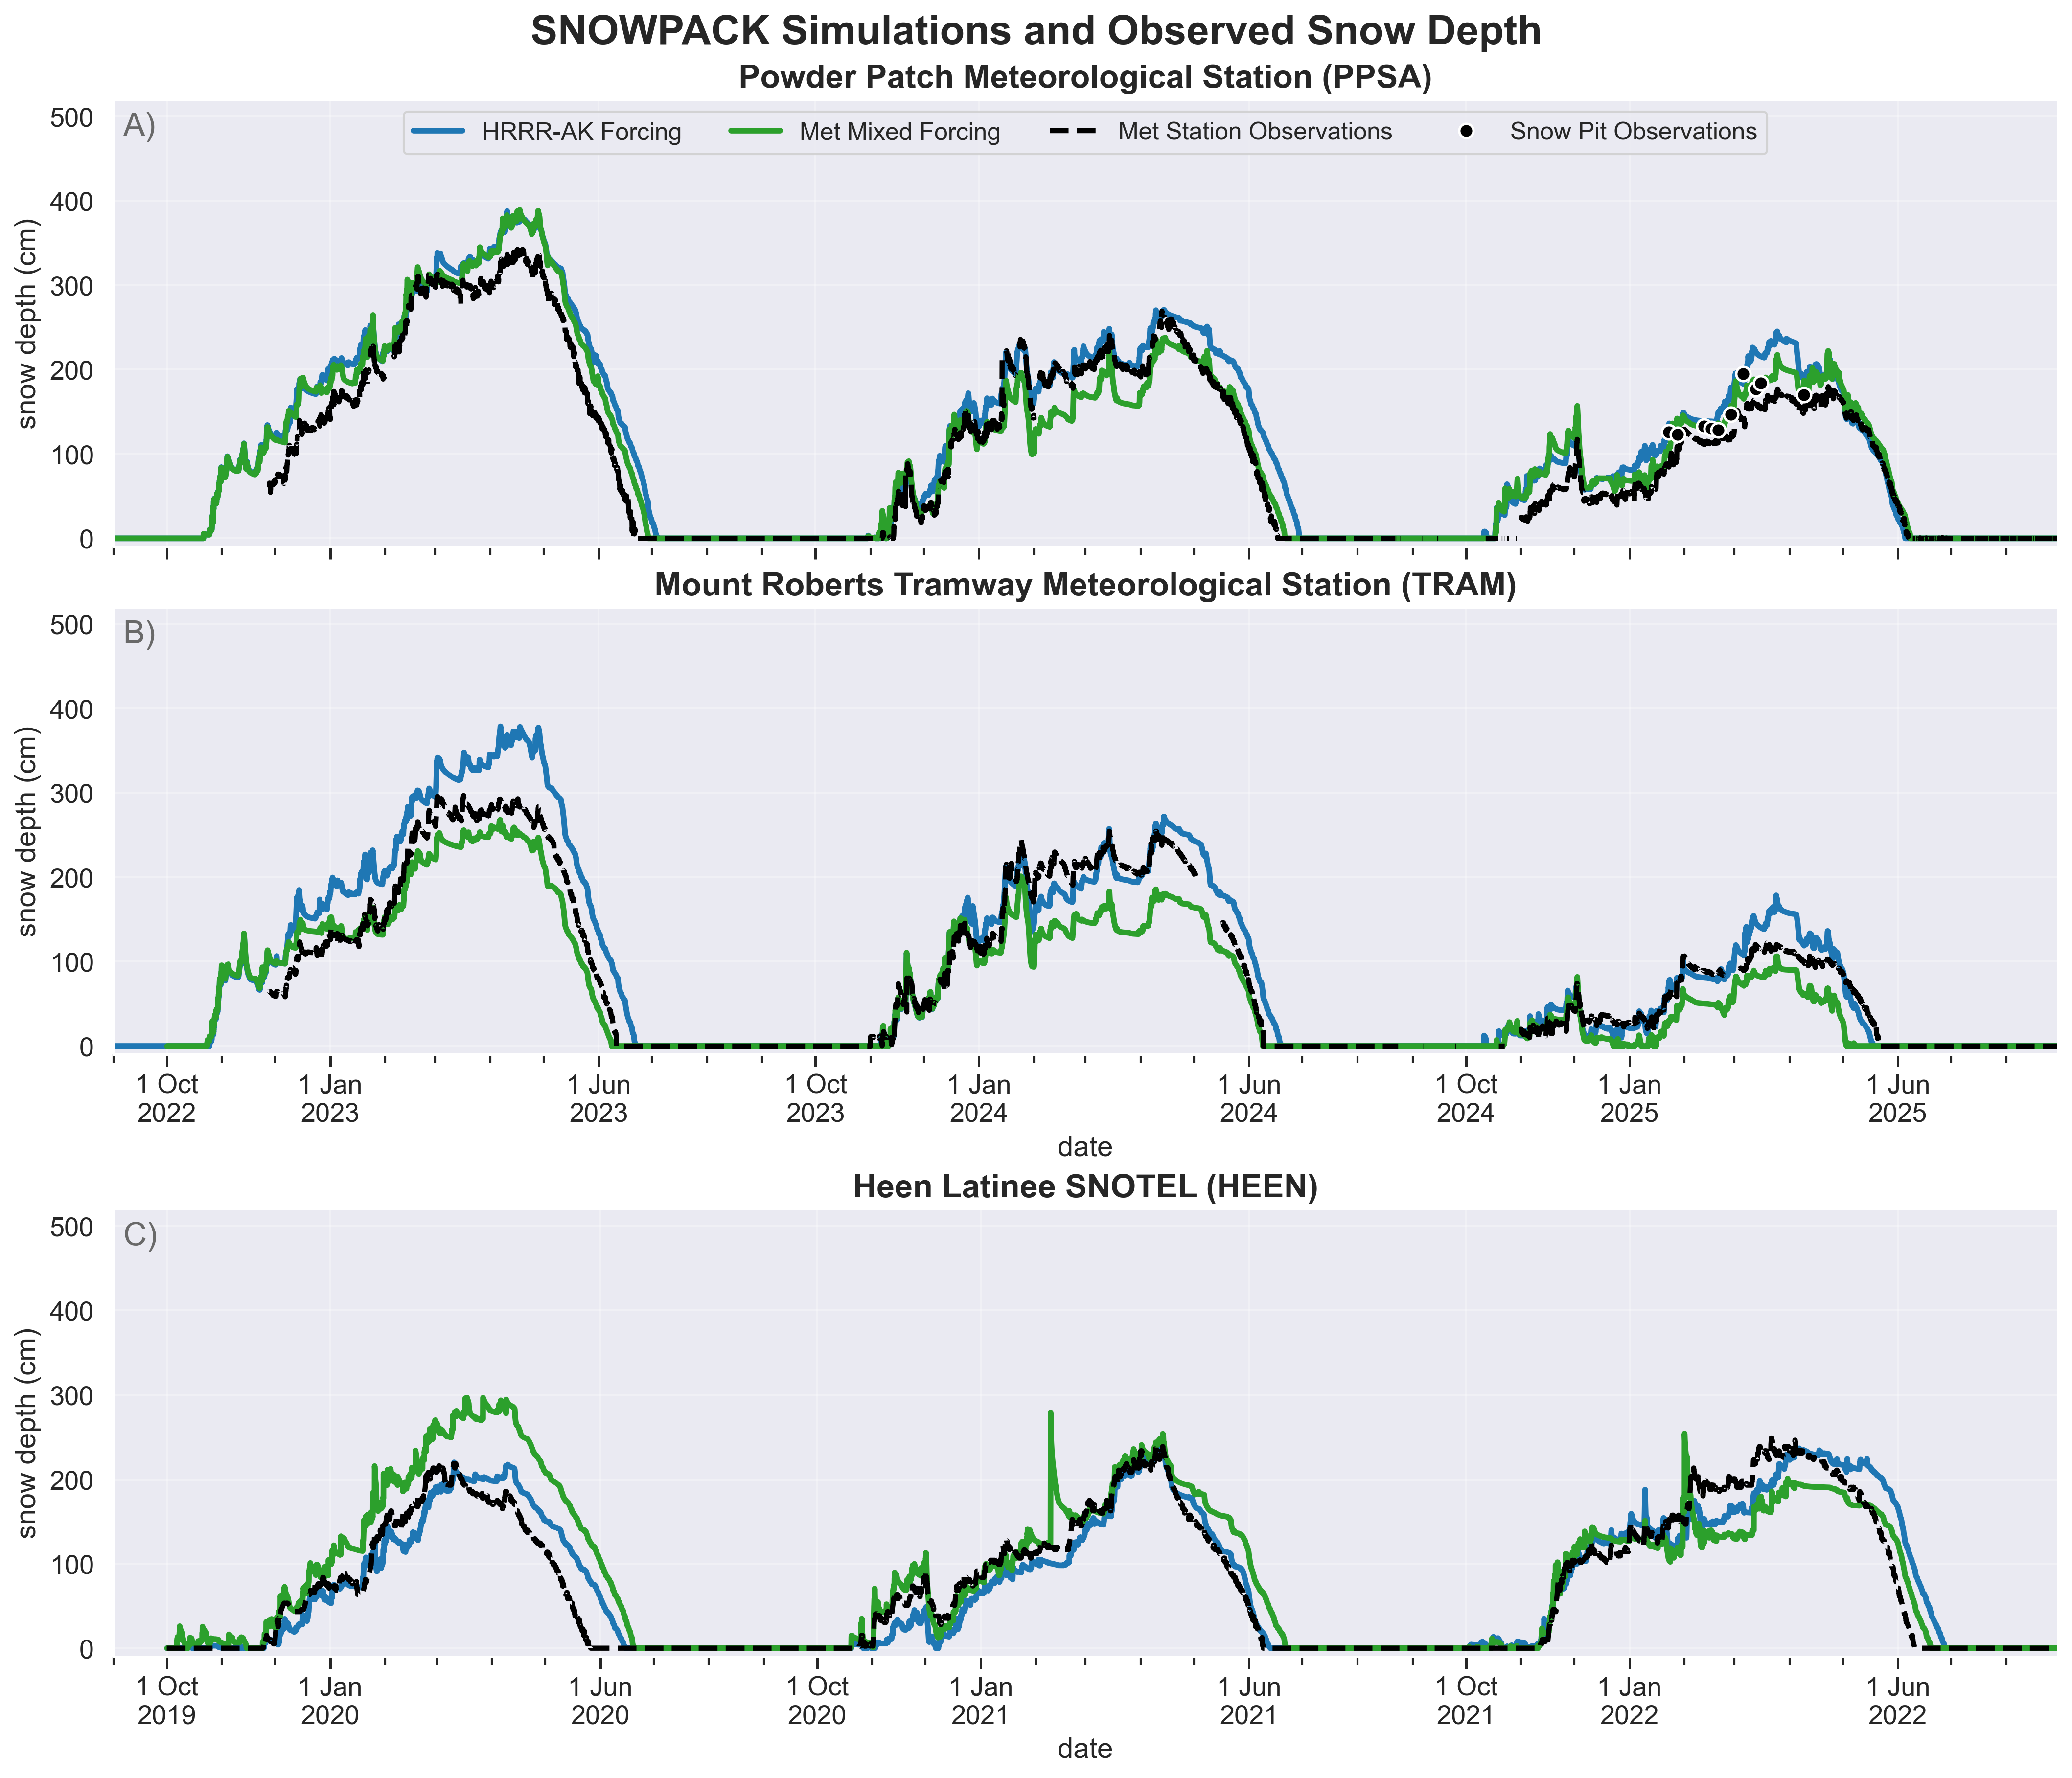

In [9]:
# ============================================================
# Select periods
# ============================================================

# HEEN -> WY2020-WY2022
heen_start = "2019-09-01"
heen_end   = "2022-08-30"

# PPSA + TRAM -> WY2023-WY2025
modern_start = "2022-09-01"
modern_end   = "2025-08-30"

# ------------------------------------------------------------
# Observations
# ------------------------------------------------------------

ds_obs_heen_plot = ds_obs_heen.sel(time=slice(heen_start, heen_end))
ds_obs_ppsa_plot = ds_obs_ppsa.sel(time=slice(modern_start, modern_end))
ds_obs_tram_plot = ds_obs_tram.sel(time=slice(modern_start, modern_end))

# ------------------------------------------------------------
# HRRR-AK simulations
# ------------------------------------------------------------


# ------------------------------------------------------------
# HRRR-AK lapse-rate simulations
# ------------------------------------------------------------

ds_snowpack_hrrrak_lapserate_heen_plot = ds_snowpack_hrrrak_lapserate_heen.sel(timestamp=slice(heen_start, heen_end))
ds_snowpack_hrrrak_lapserate_ppsa_plot = ds_snowpack_hrrrak_lapserate_ppsa.sel(timestamp=slice(modern_start, modern_end))
ds_snowpack_hrrrak_lapserate_tram_plot = ds_snowpack_hrrrak_lapserate_tram.sel(timestamp=slice(modern_start, modern_end))

# ------------------------------------------------------------
# Mixed met forcing simulations
# ------------------------------------------------------------


# ------------------------------------------------------------
# Mixed met + HRRR-AK lapse-rate temperature fill simulations
# ------------------------------------------------------------

ds_snowpack_met_hrrrak_lapserate_heen_plot = (
    ds_snowpack_met_hrrrak_lapserate_heen.sel(timestamp=slice(heen_start, heen_end))
)

ds_snowpack_met_hrrrak_lapserate_ppsa_plot = (
    ds_snowpack_met_hrrrak_lapserate_ppsa.sel(timestamp=slice(modern_start, modern_end))
)

ds_snowpack_met_hrrrak_lapserate_tram_plot = (
    ds_snowpack_met_hrrrak_lapserate_tram.sel(timestamp=slice(modern_start, modern_end))
)


# ============================================================
# Adjustable manuscript-style plotting parameters
# ============================================================

fig_width = 14
fig_height = 12
dpi = 300

title_fontsize = 20
subplot_title_fontsize = 16
axis_label_fontsize = 14
tick_fontsize = 13
legend_fontsize = 12

model_linewidth = 2.8
obs_linewidth = 2.5

major_tick_length = 6
major_tick_width = 1.2

spine_width = 1.2


# ============================================================
# Colors
# ============================================================

hrrrak_color = "tab:blue"
met_mixed_color = "tab:green"
obs_color = "black"


# ============================================================
# Create figure
# ============================================================

fig = plt.figure(
    figsize=(fig_width, fig_height),
    dpi=dpi,
    constrained_layout=True
)

ax1 = plt.subplot(3, 1, 1)
ax2 = plt.subplot(3, 1, 2, sharey=ax1)
ax3 = plt.subplot(3, 1, 3, sharey=ax1)


# ============================================================
# Site configuration
# ============================================================

sites = [
    {
        "ax": ax1,
        "site_name": "Powder Patch Meteorological Station (PPSA)",
        "hrrr_ds": ds_snowpack_hrrrak_lapserate_ppsa_plot,
        "met_ds": ds_snowpack_met_hrrrak_lapserate_ppsa_plot,
        "obs_ds": ds_obs_ppsa_plot,
        "xmin": modern_start,
        "xmax": modern_end,
    },
    {
        "ax": ax2,
        "site_name": "Mount Roberts Tramway Meteorological Station (TRAM)",
        "hrrr_ds": ds_snowpack_hrrrak_lapserate_tram_plot,
        "met_ds": ds_snowpack_met_hrrrak_lapserate_tram_plot,
        "obs_ds": ds_obs_tram_plot,
        "xmin": modern_start,
        "xmax": modern_end,
    },
    {
        "ax": ax3,
        "site_name": "Heen Latinee SNOTEL (HEEN)",
        "hrrr_ds": ds_snowpack_hrrrak_lapserate_heen_plot,
        "met_ds": ds_snowpack_met_hrrrak_lapserate_heen_plot,
        "obs_ds": ds_obs_heen_plot,
        "xmin": heen_start,
        "xmax": heen_end,
    },
]


# ============================================================
# Plot each site
# ============================================================

for site in sites:

    ax = site["ax"]

    # --------------------------------------------------------
    # HRRR-AK lapse-rate corrected forcing
    # --------------------------------------------------------

    site["hrrr_ds"].HS_mod.plot(
        ax=ax,
        color=hrrrak_color,
        linewidth=model_linewidth,
        linestyle="-",
        label="HRRR-AK Forcing",
    )

    # --------------------------------------------------------
    # Mixed met forcing with lapse-rate corrected HRRR-AK TA fill
    # --------------------------------------------------------

    site["met_ds"].HS_mod.plot(
        ax=ax,
        color=met_mixed_color,
        linewidth=model_linewidth,
        linestyle="-",
        label="Met Mixed Forcing",
    )

    # --------------------------------------------------------
    # Observed snow depth
    # --------------------------------------------------------

    site["obs_ds"].hs.plot(
        ax=ax,
        color=obs_color,
        linestyle="--",
        linewidth=obs_linewidth,
        label="Met Station Observations",
    )

    # --------------------------------------------------------
    # Axis limits
    # --------------------------------------------------------

    ax.set_xlim(
        pd.Timestamp(site["xmin"]),
        pd.Timestamp(site["xmax"])
    )

    # --------------------------------------------------------
    # Titles and labels
    # --------------------------------------------------------

    ax.set_title(
        site["site_name"],
        fontsize=subplot_title_fontsize,
        fontweight="bold",
    )

    ax.set_ylabel(
        "snow depth (cm)",
        fontsize=axis_label_fontsize,
    )

    # --------------------------------------------------------
    # Tick formatting
    # --------------------------------------------------------

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=tick_fontsize,
        length=major_tick_length,
        width=major_tick_width,
    )

    # --------------------------------------------------------
    # Spine thickness
    # --------------------------------------------------------

    for spine in ax.spines.values():
        spine.set_linewidth(spine_width)

    # --------------------------------------------------------
    # Grid
    # --------------------------------------------------------

    ax.grid(alpha=0.3)


# ============================================================
# Field snow depth measurements - PPSA WY2025
# ============================================================

ax1.plot(
    df_field_measurements.index,
    df_field_measurements["snow_depth_cm"],
    linestyle="None",
    marker="o",
    markersize=7,
    color="black",
    markerfacecolor="black",
    markeredgecolor="white",
    markeredgewidth=1.2,
    label="Snow Pit Observations",
    zorder=10,
)

# ============================================================
# Legend
# ============================================================

# One legend is sufficient because all panels contain the same datasets.
ax1.legend(
    fontsize=legend_fontsize,
    loc="upper center",
    frameon=True,
    ncol=4,
)


# ============================================================
# X-axis formatting
# ============================================================

for ax in [ax1, ax2, ax3]:

    # Major ticks: labeled dates
    ax.xaxis.set_major_locator(
        mdates.MonthLocator(bymonth=[1,6,10])
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%-d %b\n%Y")
    )

    # Minor ticks: first day of every month, no labels
    ax.xaxis.set_minor_locator(
        mdates.MonthLocator()
    )

    ax.tick_params(
        axis="x",
        which="major",
        bottom=True,
        labelbottom=True,
        labelsize=tick_fontsize,
        length=major_tick_length,
        width=major_tick_width,
    )

    ax.tick_params(
        axis="x",
        which="minor",
        bottom=True,
        labelbottom=False,
        length=4,
        width=1.0,
    )

    ax.set_xlabel(
        "date",
        fontsize=axis_label_fontsize
    )

    for label in ax.get_xticklabels():
        label.set_visible(True)


# Remove x-axis ticks and labels from panel A
ax1.set_xlabel("")

ax1.tick_params(
    axis="x",
    which="both",
    # bottom=False,
    bottom=True,
    top=False,
    labelbottom=False,
)


# ============================================================
# Shared y-axis limits
# ============================================================

ax1.set_ylim(-10, 520)


# ============================================================
# Figure title
# ============================================================

fig.suptitle(
    "SNOWPACK Simulations and Observed Snow Depth",
    fontsize=title_fontsize,
    fontweight="bold",
)


# ============================================================
# Add subplot labels
# ============================================================

xloc = 0.005
yloc = 0.92

ax1.text(
    xloc,
    yloc,
    "A)",
    transform=ax1.transAxes,
    fontsize=subplot_title_fontsize,
    color="dimgrey",
)

ax2.text(
    xloc,
    yloc,
    "B)",
    transform=ax2.transAxes,
    fontsize=subplot_title_fontsize,
    color="dimgrey",
)

ax3.text(
    xloc,
    yloc,
    "C)",
    transform=ax3.transAxes,
    fontsize=subplot_title_fontsize,
    color="dimgrey",
)


# ============================================================
# Save figure
# ============================================================

if SAVE_FIGURES:
    plt.savefig(
        "/home/cassie/python/repos/snow_modeling_point/figures/figure4_soil.pdf",
        bbox_inches="tight"
    )

if SAVE_FIGURES:
    plt.savefig(
        "/home/cassie/python/repos/snow_modeling_point/figures/figure4_soil.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()


## PPSA WY2025: snow-pit comparison

PPSA only, from October 1, 2024 through September 30, 2025. The same two lapse-rate forcing simulations, station observations, snow-depth units, colors, and snow-pit markers as the main figure are retained. The ten snow-pit depths are filtered to this water year and shown individually. Dates in the field file have day resolution; no measurement time is inferred. This diagnostic figure displays inline and is not automatically exported.


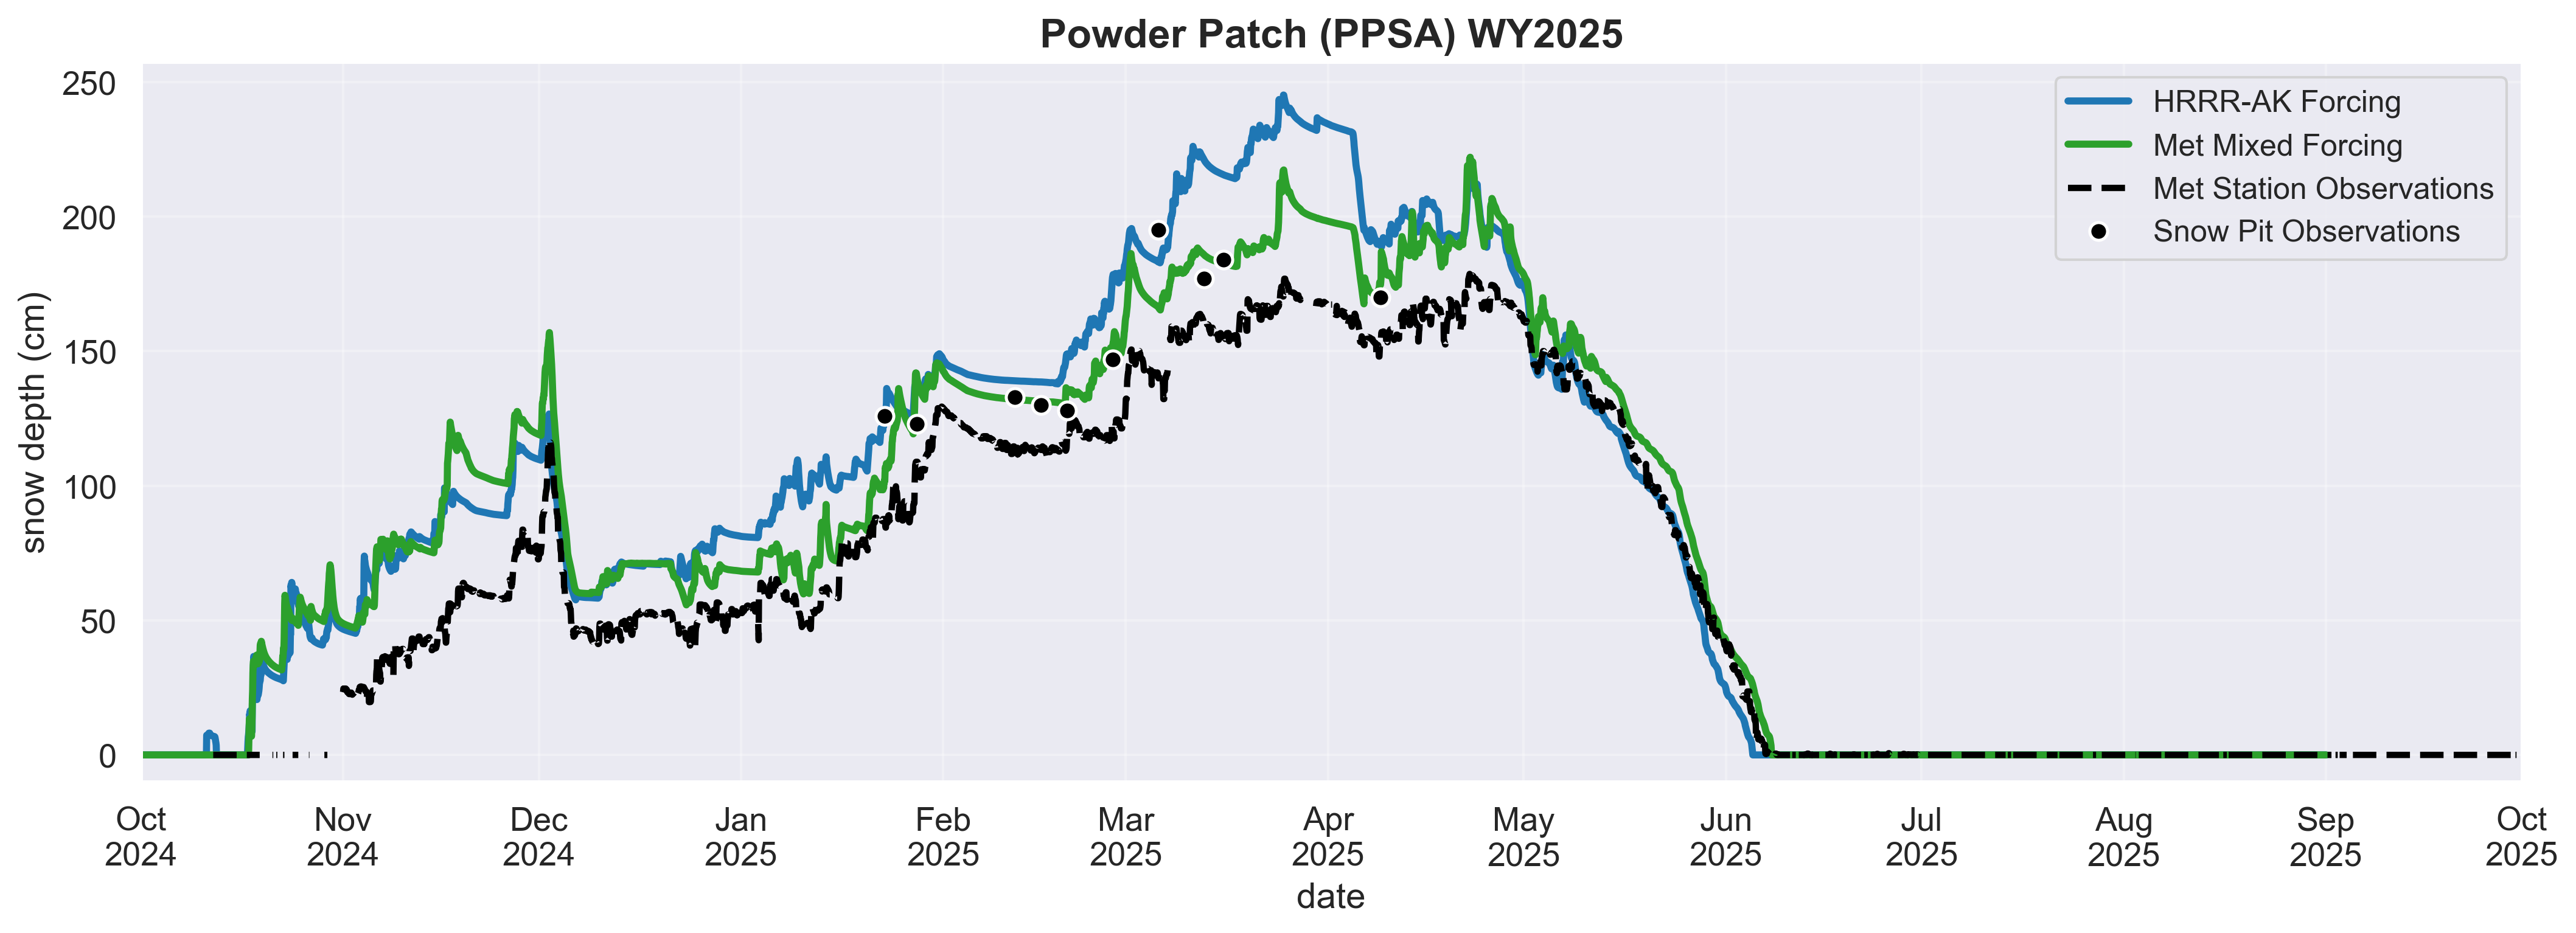

In [10]:
# PPSA only: select WY2025 from the original datasets, not other site/year panels.
ppsa_wy2025_start = pd.Timestamp("2024-10-01")
ppsa_wy2025_end = pd.Timestamp("2025-10-01") - pd.Timedelta(nanoseconds=1)
ppsa_wy2025_hrrr = ds_snowpack_hrrrak_lapserate_ppsa.sel(
    timestamp=slice(ppsa_wy2025_start, ppsa_wy2025_end))
ppsa_wy2025_met = ds_snowpack_met_hrrrak_lapserate_ppsa.sel(
    timestamp=slice(ppsa_wy2025_start, ppsa_wy2025_end))
ppsa_wy2025_obs = ds_obs_ppsa.sel(time=slice(ppsa_wy2025_start, ppsa_wy2025_end))
ppsa_wy2025_pits = df_field_measurements.loc[
    (df_field_measurements.index >= ppsa_wy2025_start)
    & (df_field_measurements.index <= ppsa_wy2025_end)
].sort_index()

fig_ppsa_wy2025, ax_ppsa_wy2025 = plt.subplots(
    figsize=(fig_width, 5), dpi=dpi, constrained_layout=True)
ppsa_wy2025_hrrr.HS_mod.plot(ax=ax_ppsa_wy2025, color="tab:blue",
    linewidth=model_linewidth, linestyle="-", label="HRRR-AK Forcing")
ppsa_wy2025_met.HS_mod.plot(ax=ax_ppsa_wy2025, color="tab:green",
    linewidth=model_linewidth, linestyle="-", label="Met Mixed Forcing")
ppsa_wy2025_obs.hs.plot(ax=ax_ppsa_wy2025, color="black",
    linewidth=obs_linewidth, linestyle="--", label="Met Station Observations")
ax_ppsa_wy2025.plot(ppsa_wy2025_pits.index, ppsa_wy2025_pits["snow_depth_cm"],
    linestyle="None", marker="o", markersize=7, color="black",
    markerfacecolor="black", markeredgecolor="white", markeredgewidth=1.2,
    label="Snow Pit Observations", zorder=10)
ax_ppsa_wy2025.set_xlim(ppsa_wy2025_start, ppsa_wy2025_end)
ax_ppsa_wy2025.set_ylim(bottom=-10)
ax_ppsa_wy2025.set_title("Powder Patch (PPSA) WY2025",
    fontsize=subplot_title_fontsize, fontweight="bold")
ax_ppsa_wy2025.set_ylabel("snow depth (cm)", fontsize=axis_label_fontsize)
ax_ppsa_wy2025.set_xlabel("date", fontsize=axis_label_fontsize)
ax_ppsa_wy2025.xaxis.set_major_locator(mdates.MonthLocator())
ax_ppsa_wy2025.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax_ppsa_wy2025.tick_params(axis="both", labelsize=tick_fontsize,
    length=major_tick_length, width=major_tick_width)
for spine in ax_ppsa_wy2025.spines.values():
    spine.set_linewidth(spine_width)
ax_ppsa_wy2025.grid(alpha=0.3)
ax_ppsa_wy2025.legend(fontsize=legend_fontsize, loc="upper right", frameon=True)
plt.show()
